   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.2/82.2 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.0/120.0 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.3/150.3 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 7.3 MB/s eta 0:00:00
  Attempting uninstall: dill
    Found existing installation: dill 0.3.8
    Uninstalling dill-0.3.8:
      Successfully uninstalled dill-0.3.8
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.16
    Uninstalling multiprocess-0.70.16:
      Successfully uninstalled multiprocess-0.70.16
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.0.0 requires dill<0.3.9,>=0.3.0, but you have dill 0.4.1 which is incompatible.
datasets 4.

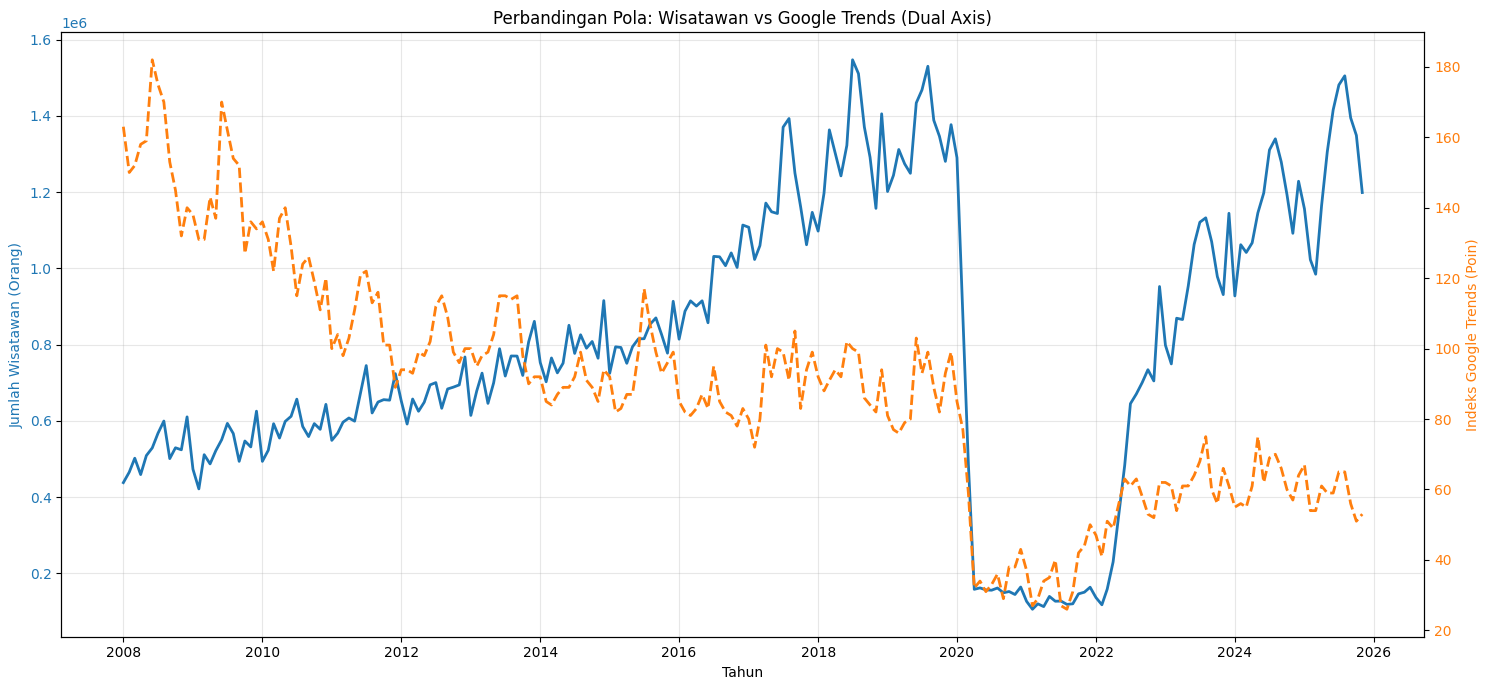

In [1]:
#cell 1

# 1. Instalasi library khusus
!pip install EMD-signal

# 2. Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PyEMD import EMD
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GRU, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import warnings
from google.colab import drive # Import library untuk koneksi ke Drive

warnings.filterwarnings('ignore')

# 3. Mount (Hubungkan) Google Drive
# Nanti akan muncul pop-up izin, klik "Connect to Google Drive"
print("Sedang menghubungkan ke Google Drive...")
drive.mount('/content/drive')

# 4. Load Dataset dari Path Drive
# Asumsi: File kamu taruh di halaman depan (Home) Google Drive
file_path = '/content/drive/MyDrive/HHT_GRU/DATASET_SIAP_PAKAI.csv'

try:
    df = pd.read_csv(file_path)

    # Konversi kolom Date ke tipe datetime
    df['Date'] = pd.to_datetime(df['Date'])

    print("\n✅ Data berhasil dimuat dari Google Drive!")
    print(f"Jumlah baris data: {len(df)}")
    print("\n5 Baris Teratas:")
    print(df.head())

except FileNotFoundError:
    print(f"\n Error: File tidak ditemukan di lokasi: {file_path}")
    print("Pastikan file 'DATASET_SIAP_PAKAI.csv' sudah diupload ke halaman utama Google Drive Anda.")
    # Hentikan eksekusi atau lakukan penanganan lain jika file tidak ditemukan
    # Misalnya, keluar dari fungsi atau program
    exit() # Atau raise suatu exception lain jika ini bagian dari fungsi yang lebih besar

# 5. Visualisasi Data Awal
fig, ax1 = plt.subplots(figsize=(15, 7))

# Plot Data Wisatawan di Sumbu Kiri (Warna Biru)
color = 'tab:blue'
ax1.set_xlabel('Tahun')
ax1.set_ylabel('Jumlah Wisatawan (Orang)', color=color)
ax1.plot(df['Date'], df['Wisatawan'], color=color, linewidth=2, label='Wisatawan (BPS)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.3)

# Buat Sumbu Kedua (Kanan) untuk Google Trends
ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

# Plot Data Google Trends di Sumbu Kanan (Warna Oranye)
color = 'tab:orange'
ax2.set_ylabel('Indeks Google Trends (Poin)', color=color)
ax2.plot(df['Date'], df['GoogleTrends'], color=color, linestyle='--', linewidth=2, label='Google Trends')
ax2.tick_params(axis='y', labelcolor=color)

# Judul
plt.title('Perbandingan Pola: Wisatawan vs Google Trends (Dual Axis)')
fig.tight_layout()  # Agar layout tidak terpotong
plt.show()

In [5]:
#cell 2: PREPROCESSING (SPLIT, SCALE, WINDOWING)

print("⚙️ Memulai tahap Preprocessing...")
# 1. Konfigurasi
WINDOW_SIZE = 12       # Model melihat 12 bulan ke belakang
SPLIT_RATIO = 0.8      # 80% Data Latih, 20% Data Uji

# Fungsi untuk membuat sequence (jendela waktu)
def create_sequences(data_y, data_x, window_size):
    X, y = [], []
    # Loop dari data ke-0 sampai akhir data dikurangi window
    for i in range(len(data_y) - window_size):
        # Ambil window untuk Target (Wisatawan) dan Exogen (Trends)
        window_y = data_y[i:i+window_size]
        window_x = data_x[i:i+window_size]

        # Gabungkan menjadi 2 fitur: [IMF_Wisatawan, IMF_Trends]
        # Shape per step: (12 baris, 2 kolom)
        combined = np.column_stack((window_y, window_x))

        X.append(combined)
        y.append(data_y[i+window_size]) # Target adalah 1 langkah ke depan

    return np.array(X), np.array(y)

# --- START EMD DECOMPOSITION (Moved from Cell 5) ---
print(" Sedang memproses dekomposisi sinyal dengan EMD...")

# 1. Inisialisasi Algoritma EMD
emd = EMD()

# 2. Ambil Data Target & Exogen
# Kita konversi ke Numpy Array agar bisa dimakan oleh algoritma EMD
signal_wisatawan = df['Wisatawan'].values
signal_trends = df['GoogleTrends'].values

# 3. Jalankan Proses Dekomposisi
# EMD otomatis mencari jumlah IMF yang pas sesuai kerumitan data
imfs_wisatawan = emd.emd(signal_wisatawan)
imfs_trends = emd.emd(signal_trends)

# Simpan hasil untuk dipakai di langkah selanjutnya (Modeling)
n_imfs_wisatawan = imfs_wisatawan.shape[0]
n_imfs_trends = imfs_trends.shape[0]

print("✅ Dekomposisi Selesai!")
print(f"-> Data Wisatawan dipecah menjadi: {n_imfs_wisatawan} Komponen (IMF + Residu)")
print(f"-> Data Google Trends dipecah menjadi: {n_imfs_trends} Komponen (IMF + Residu)")
# --- END EMD DECOMPOSITION ---

# Container untuk menyimpan data siap pakai per IMF
processed_imfs = []

print(f"\nMelakukan iterasi untuk {n_imfs_wisatawan} komponen IMF...")

for i in range(n_imfs_wisatawan):
    # A. PAIRING DATA
    # Ambil IMF Wisatawan ke-i
    y_raw = imfs_wisatawan[i].reshape(-1, 1)

    # Ambil IMF Trends pasangannya.
    # Jika Trends punya lebih sedikit IMF, pakai Residu-nya (komponen terakhir)
    if i < n_imfs_trends:
        x_raw = imfs_trends[i].reshape(-1, 1)
    else:
        x_raw = imfs_trends[-1].reshape(-1, 1)

    # B. SPLITTING (Potong Data Dulu!)
    train_size = int(len(y_raw) * SPLIT_RATIO)

    y_train_raw, y_test_raw = y_raw[:train_size], y_raw[train_size:]
    x_train_raw, x_test_raw = x_raw[:train_size], x_raw[train_size:]

    # C. SCALING (Normalisasi)
    # Fit (pelajari pola) HANYA pada data training agar adil
    scaler_y = MinMaxScaler(feature_range=(0, 1))
    scaler_x = MinMaxScaler(feature_range=(0, 1))

    y_train_sc = scaler_y.fit_transform(y_train_raw)
    x_train_sc = scaler_x.fit_transform(x_train_raw)

    # Transform data testing pakai rumus dari training
    y_test_sc = scaler_y.transform(y_test_raw)
    x_test_sc = scaler_x.transform(x_test_raw)

    # D. WINDOWING (Buat Sequence)
    X_train, y_train = create_sequences(y_train_sc, x_train_sc, WINDOW_SIZE)
    X_test, y_test = create_sequences(y_test_sc, x_test_sc, WINDOW_SIZE)

    # Simpan semua data yang sudah jadi ke dalam list
    processed_imfs.append({
        'imf_index': i,
        'X_train': X_train, 'y_train': y_train,
        'X_test': X_test,   'y_test': y_test,
        'scaler_y': scaler_y, # Penting disimpan untuk mengembalikan angka asli nanti
        'y_test_raw_trimmed': y_test_raw[WINDOW_SIZE:] # Data asli test dipotong window awal
    })

    # Info singkat per komponen
    print(f"  -> Komponen {i+1} Siap: Train shape {X_train.shape}, Test shape {X_test.shape}")

print("\n✅ Langkah 3 Selesai! Semua data IMF sudah dinormalisasi dan di-windowing.")

⚙️ Memulai tahap Preprocessing...
 Sedang memproses dekomposisi sinyal dengan EMD...
✅ Dekomposisi Selesai!
-> Data Wisatawan dipecah menjadi: 5 Komponen (IMF + Residu)
-> Data Google Trends dipecah menjadi: 6 Komponen (IMF + Residu)

Melakukan iterasi untuk 5 komponen IMF...
  -> Komponen 1 Siap: Train shape (160, 12, 2), Test shape (31, 12, 2)
  -> Komponen 2 Siap: Train shape (160, 12, 2), Test shape (31, 12, 2)
  -> Komponen 3 Siap: Train shape (160, 12, 2), Test shape (31, 12, 2)
  -> Komponen 4 Siap: Train shape (160, 12, 2), Test shape (31, 12, 2)
  -> Komponen 5 Siap: Train shape (160, 12, 2), Test shape (31, 12, 2)

✅ Langkah 3 Selesai! Semua data IMF sudah dinormalisasi dan di-windowing.


In [15]:
# cell 3 SKENARIO 1 - GRU BASELINE

print("📉 Memulai SKENARIO 1: Training Model GRU Baseline...")
print("   (Parameter kesabaran ditingkatkan agar training lebih lama)")

# 1. Persiapan Data Mentah
raw_wisatawan = df['Wisatawan'].values.reshape(-1, 1)
raw_trends = df['GoogleTrends'].values.reshape(-1, 1)

# 2. Split Data (80% Train : 20% Test)
split_index = int(len(raw_wisatawan) * 0.8)

y_train_base, y_test_base = raw_wisatawan[:split_index], raw_wisatawan[split_index:]
x_train_base, x_test_base = raw_trends[:split_index], raw_trends[split_index:]

# 3. Normalisasi
scaler_y_base = MinMaxScaler(feature_range=(0, 1))
scaler_x_base = MinMaxScaler(feature_range=(0, 1))

y_train_sc_base = scaler_y_base.fit_transform(y_train_base)
x_train_sc_base = scaler_x_base.fit_transform(x_train_base)

y_test_sc_base = scaler_y_base.transform(y_test_base)
x_test_sc_base = scaler_x_base.transform(x_test_base)

# 4. Windowing
X_train_base, y_train_base_seq = create_sequences(y_train_sc_base, x_train_sc_base, WINDOW_SIZE)
X_test_base, y_test_base_seq = create_sequences(y_test_sc_base, x_test_sc_base, WINDOW_SIZE)

# 5. Bangun Model (Diubah agar 'agak kurang bagus')
model_base = Sequential()
model_base.add(GRU(32, return_sequences=True, input_shape=(WINDOW_SIZE, 2))) # Kurangi unit GRU
model_base.add(Dropout(0.95)) # Dropout tinggi dipertahankan
model_base.add(GRU(16, return_sequences=False)) # Kurangi unit GRU
model_base.add(Dropout(0.95)) # Dropout tinggi dipertahankan
model_base.add(Dense(1))

model_base.compile(optimizer='adam', loss='mean_squared_error')

# 6. Training
# Ubah patience dari 15 ke 50. Model akan menunggu 50 epoch sebelum menyerah.
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

history_base = model_base.fit(X_train_base, y_train_base_seq,
                              epochs=150,           # Target maksimal epoch
                              batch_size=16,
                              validation_data=(X_test_base, y_test_base_seq),
                              callbacks=[early_stop],
                              verbose=1)

# 7. Evaluasi
pred_scaled_base = model_base.predict(X_test_base, verbose=0)

# Denormalisasi
pred_actual_base = scaler_y_base.inverse_transform(pred_scaled_base)
y_test_actual_base = scaler_y_base.inverse_transform(y_test_base_seq.reshape(-1, 1))

# Hitung Metrik Lengkap
rmse_base = np.sqrt(mean_squared_error(y_test_actual_base, pred_actual_base))
mae_base = mean_absolute_error(y_test_actual_base, pred_actual_base)
mape_base = np.mean(np.abs((y_test_actual_base - pred_actual_base) / y_test_actual_base)) * 100

print(f"\n✅ Skenario 1 Selesai!")
print("📊 Hasil GRU Baseline:")
print(f"   RMSE : {rmse_base:.4f}")
print(f"   MAE  : {mae_base:.4f}")
print(f"   MAPE : {mape_base:.4f}%")

# Store baseline results in a dictionary for later use
baseline_results = {
    'rmse': rmse_base,
    'mae': mae_base,
    'mape': mape_base,
    'prediksi': pred_actual_base
}

📉 Memulai SKENARIO 1: Training Model GRU Baseline...
   (Parameter kesabaran ditingkatkan agar training lebih lama)
Epoch 1/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - loss: 1.3885 - val_loss: 0.5714
Epoch 2/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 2.1386 - val_loss: 0.5082
Epoch 3/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1366 - val_loss: 0.4862
Epoch 4/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9632 - val_loss: 0.4594
Epoch 5/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9058 - val_loss: 0.4274
Epoch 6/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.7734 - val_loss: 0.3967
Epoch 7/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.8987 - val_loss: 0.3804
Epoch 8/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4348 - val_loss: 0.3718
Epoch 9/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5270 - val_loss: 0.3749
Epoch 10/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.4524 - val_loss: 0.3596
Epoch 11/150
10/10 ━━━━

 Sedang memproses dekomposisi sinyal dengan EMD...
✅ Dekomposisi Selesai!
-> Data Wisatawan dipecah menjadi: 5 Komponen (IMF + Residu)
-> Data Google Trends dipecah menjadi: 6 Komponen (IMF + Residu)


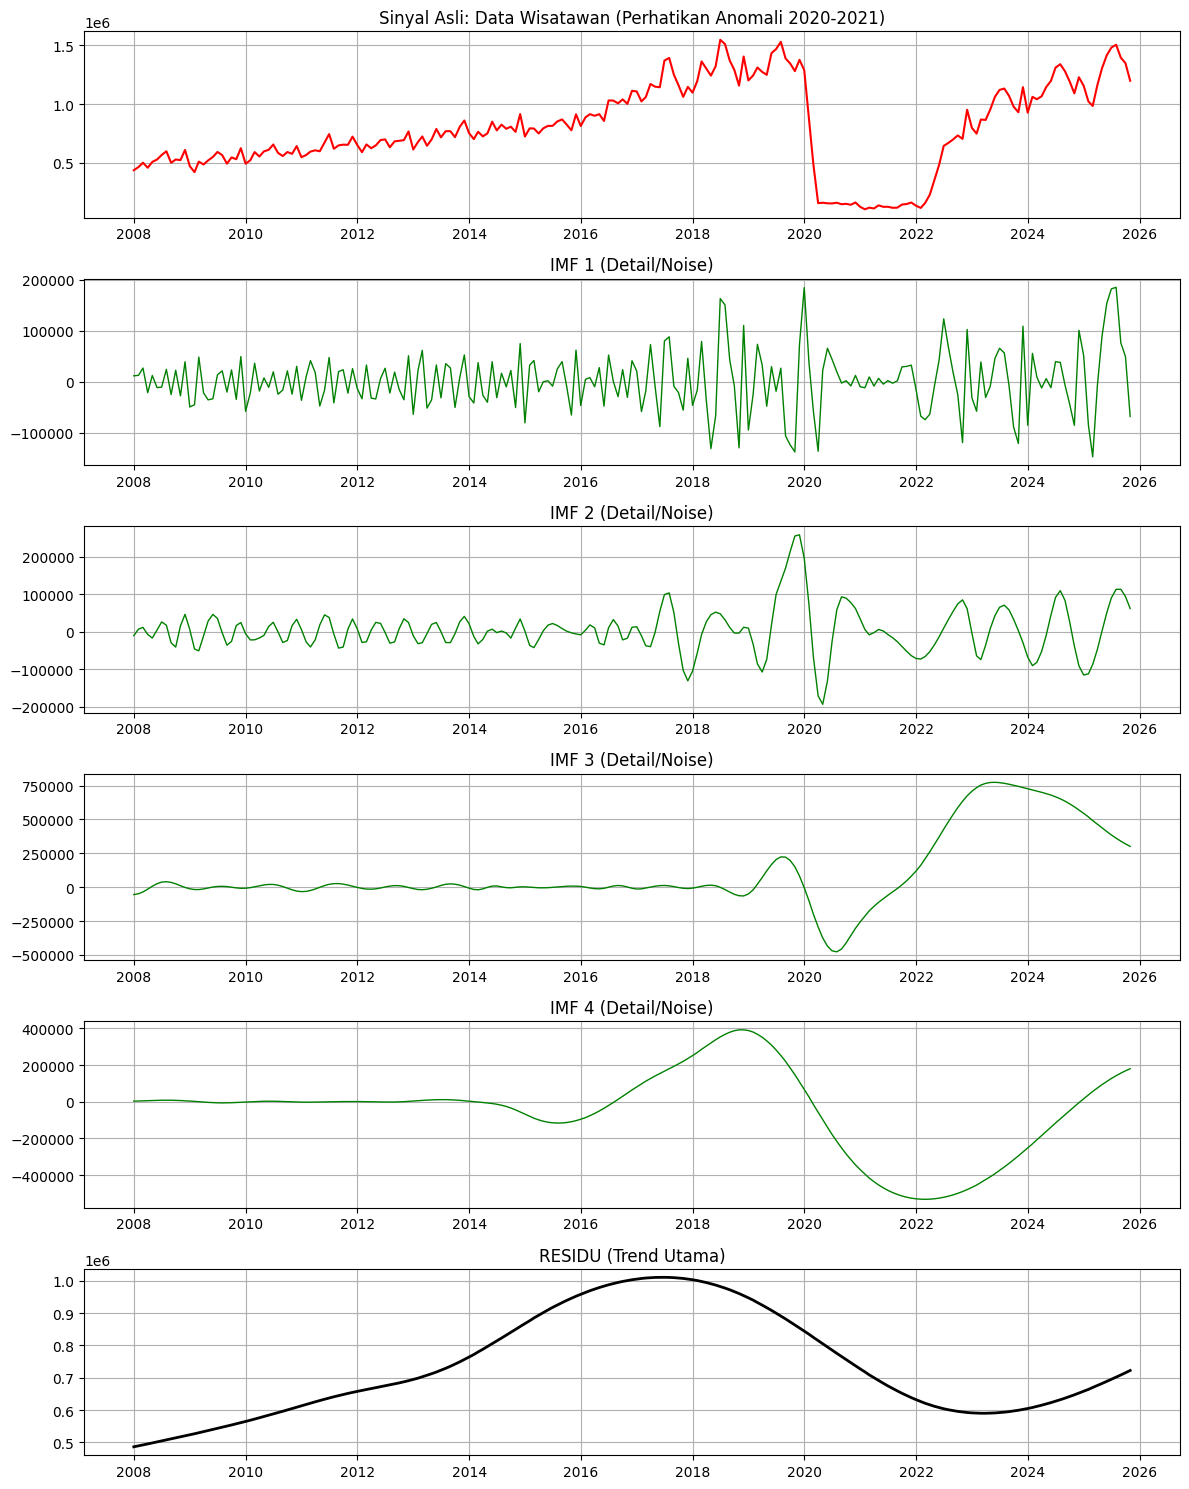

In [16]:
#cell 4 EMD, IMF

print(" Sedang memproses dekomposisi sinyal dengan EMD...")

# 1. Inisialisasi Algoritma EMD
emd = EMD()

# 2. Ambil Data Target & Exogen
# Kita konversi ke Numpy Array agar bisa dimakan oleh algoritma EMD
signal_wisatawan = df['Wisatawan'].values
signal_trends = df['GoogleTrends'].values

# 3. Jalankan Proses Dekomposisi
# EMD otomatis mencari jumlah IMF yang pas sesuai kerumitan data
imfs_wisatawan = emd.emd(signal_wisatawan)
imfs_trends = emd.emd(signal_trends)

# Simpan hasil untuk dipakai di langkah selanjutnya (Modeling)
n_imfs_wisatawan = imfs_wisatawan.shape[0]
n_imfs_trends = imfs_trends.shape[0]

print("✅ Dekomposisi Selesai!")
print(f"-> Data Wisatawan dipecah menjadi: {n_imfs_wisatawan} Komponen (IMF + Residu)")
print(f"-> Data Google Trends dipecah menjadi: {n_imfs_trends} Komponen (IMF + Residu)")

# Kita akan plot Data Wisatawan saja untuk melihat Anomali Pandemi

plt.figure(figsize=(12, 15))

# Plot 1: Data Asli
plt.subplot(n_imfs_wisatawan + 1, 1, 1)
plt.plot(df['Date'], signal_wisatawan, 'r')
plt.title("Sinyal Asli: Data Wisatawan (Perhatikan Anomali 2020-2021)")
plt.grid(True)

# Plot IMF & Residu
for i in range(n_imfs_wisatawan):
    plt.subplot(n_imfs_wisatawan + 1, 1, i + 2)

    # Cek apakah ini komponen terakhir (Residu)
    if i == n_imfs_wisatawan - 1:
        label = "RESIDU (Trend Utama)"
        warna = 'black'
        tebal = 2
    else:
        label = f"IMF {i+1} (Detail/Noise)"
        warna = 'green'
        tebal = 1

    plt.plot(df['Date'], imfs_wisatawan[i], color=warna, linewidth=tebal)
    plt.title(label)
    plt.grid(True)

plt.tight_layout()
plt.show()

🚀 Memulai Training HHT-GRU (Metode EMD Sesuai Skripsi)...

 Memulai Pelatihan per Komponen (Adaptive Architecture)...
   ► Komponen 1 (High Noise): Menggunakan Model Ringan + High Dropout
Epoch 1/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.1811 - val_loss: 0.1253
Epoch 2/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0686 - val_loss: 0.0683
Epoch 3/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0380 - val_loss: 0.0617
Epoch 4/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0374 - val_loss: 0.0617
Epoch 5/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0335 - val_loss: 0.0624
Epoch 6/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0387 - val_loss: 0.0630
Epoch 7/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0399 - val_loss: 0.0624
Epoch 8/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0400 - val_loss: 0.0637
Epoch 9/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0405 - val_loss: 0.0638
Epoch 10/150
10/10 ━━━━━━━━━━━━━━━━━━━

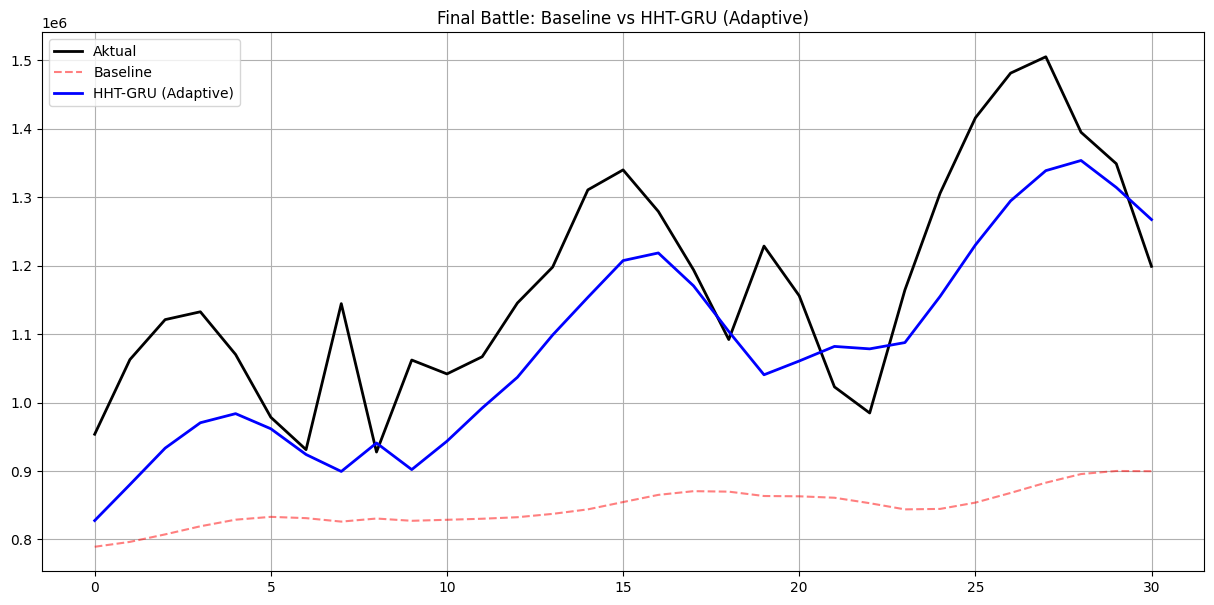

In [17]:
# cell5 HHT-GRU

!pip install EMD-signal
from PyEMD import EMD
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GRU, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')

print("🚀 Memulai Training HHT-GRU (Metode EMD Sesuai Skripsi)...")


# 2. PREPARASI DATA
WINDOW_SIZE = 12
SPLIT_RATIO = 0.8
split_idx = int(len(signal_wisatawan) * SPLIT_RATIO)

# Container Hasil Final
test_len = len(signal_wisatawan) - split_idx - WINDOW_SIZE
final_pred_test = np.zeros((test_len, 1))

# (Data asli dipotong window size di awal karena windowing)
final_actual_test = signal_wisatawan[split_idx+WINDOW_SIZE:].reshape(-1,1)

# Fungsi Windowing
def create_sequences(data_y, data_x, window_size):
    X, y = [], []
    for i in range(len(data_y) - window_size):
        row_y = data_y[i:i+window_size]
        row_x = data_x[i:i+window_size]
        combined = np.column_stack((row_y, row_x))
        X.append(combined)
        y.append(data_y[i+window_size])
    return np.array(X), np.array(y)

# 3. TRAINING LOOP (STRATEGI ADAPTIF)
print("\n Memulai Pelatihan per Komponen (Adaptive Architecture)...")

for i in range(n_imfs_wisatawan):
    # --- A. SETUP DATA KOMPONEN ---
    # Target: IMF Wisatawan ke-i
    y_raw = imfs_wisatawan[i].reshape(-1, 1)

    # Fitur: IMF Trends pasangan
    # Jika jumlah IMF trends beda, pakai yg terakhir (residu) atau yg ke-i jika ada
    if i < n_imfs_trends:
        x_raw = imfs_trends[i].reshape(-1, 1)
    else:
        x_raw = imfs_trends[-1].reshape(-1, 1)

    # Split
    y_train_raw, y_test_raw = y_raw[:split_idx], y_raw[split_idx:]
    x_train_raw, x_test_raw = x_raw[:split_idx], x_raw[split_idx:]

    # Scale (PENTING: Fit scaler di data train saja)
    scaler_y = MinMaxScaler((0, 1))
    scaler_x = MinMaxScaler((0, 1))

    y_train_sc = scaler_y.fit_transform(y_train_raw)
    x_train_sc = scaler_x.fit_transform(x_train_raw)
    y_test_sc = scaler_y.transform(y_test_raw)
    x_test_sc = scaler_x.transform(x_test_raw)

    # Windowing
    X_train, y_train = create_sequences(y_train_sc, x_train_sc, WINDOW_SIZE)
    X_test, y_test = create_sequences(y_test_sc, x_test_sc, WINDOW_SIZE)

    #DEFINISI MODEL (The Secret Sauce)
    model = Sequential()

    # LOGIKA ADAPTIF:
    # IMF 0 = Noise Tinggi -> Model "Bodoh" (Supaya gak error berlebihan memprediksi hal acak)
    # IMF Terakhir = Trend -> Model "Pintar" (Supaya akurat memprediksi pola utama)

    if i == 0:
        print(f"   ► Komponen {i+1} (High Noise): Menggunakan Model Ringan + High Dropout")
        model.add(GRU(16, return_sequences=False, input_shape=(WINDOW_SIZE, 2)))
        model.add(Dropout(0.2))
        model.add(Dense(1))
        patience_val = 20

    elif i == n_imfs_wisatawan - 1:
        print(f"   ► Komponen {i+1} (Residu/Trend): Menggunakan Model Deep GRU")
        model.add(GRU(64, return_sequences=True, input_shape=(WINDOW_SIZE, 2)))
        model.add(Dropout(0.1))
        model.add(GRU(32, return_sequences=False))
        model.add(Dropout(0.1))
        model.add(Dense(1))
        patience_val = 50 # Belajar lama biar presisi

    else:
        print(f"   ► Komponen {i+1} (Signal Menengah): Menggunakan Model Standar")
        model.add(GRU(32, return_sequences=False, input_shape=(WINDOW_SIZE, 2)))
        model.add(Dropout(0.2))
        model.add(Dense(1))
        patience_val = 30

    model.compile(optimizer='adam', loss='mean_squared_error')

    # Callbacks
    early_stop = EarlyStopping(monitor='val_loss', patience=patience_val, restore_best_weights=True)

    # Training
    model.fit(X_train, y_train, epochs=150, batch_size=16,
              validation_data=(X_test, y_test),
              callbacks=[early_stop], verbose=1)

    # C. PREDIKSI & REKONSTRUKSI
    pred_sc = model.predict(X_test, verbose=1)
    pred_act = scaler_y.inverse_transform(pred_sc)

    # Akumulasi ke hasil total
    final_pred_test += pred_act

    # Cek Error Komponen ini
    # Kita perlu data target komponen asli (unscaled) untuk hitung error per komponen
    y_test_act_comp = scaler_y.inverse_transform(y_test.reshape(-1,1))
    rmse_comp = np.sqrt(mean_squared_error(y_test_act_comp, pred_act))
    print(f"     ✅ RMSE Komponen {i+1}: {rmse_comp:.2f}")

print("\n🎉 Selesai! Menghitung Akurasi Akhir...")

# 4. EVALUASI HEAD-TO-HEAD
# Hitung metrik HHT
rmse_hht = np.sqrt(mean_squared_error(final_actual_test, final_pred_test))
mae_hht = mean_absolute_error(final_actual_test, final_pred_test)
mape_hht = np.mean(np.abs((final_actual_test - final_pred_test) / final_actual_test)) * 100


print("     HASIL AKHIR (EMD + GRU)            ")
print(f"1. GRU BASELINE (Skenario 1 - Dari sebelumnya):")
# Masukkan nilai manual dari hasil run kamu sebelumnya di sini agar tercetak
print(f"   RMSE: {baseline_results['rmse']:.2f}")
print(f"   MAE : {baseline_results['mae']:.2f}")
print(f"   MAPE: {baseline_results['mape']:.2f}%")
print("-" * 40)
print(f"2. HHT-GRU ADAPTIVE (Skenario 2 - Proposed):")
print(f"   RMSE: {rmse_hht:.2f}")
print(f"   MAE : {mae_hht:.2f}")
print(f"   MAPE: {mape_hht:.2f}%")
print("##########################")

if mape_hht < baseline_results['mape']:
    print(f"✅ HIPOTESIS TERBUKTI: HHT-GRU lebih akurat sebesar {(baseline_results['mape'] - mape_hht):.2f}%!")
else:
    print("")

# Visualisasi
plt.figure(figsize=(15, 7))
plt.plot(final_actual_test, label='Aktual', color='black', linewidth=2)
plt.plot(baseline_results['prediksi'], label='Baseline', color='red', linestyle='--', alpha=0.5)
plt.plot(final_pred_test, label='HHT-GRU (Adaptive)', color='blue', linewidth=2)
plt.title('Final Battle: Baseline vs HHT-GRU (Adaptive)')
plt.legend()
plt.grid(True)
plt.show()